# Práctico: comparar detectores sobre un servicio más difícil (estudiantes)

Las clases 9–11 cubrieron cuatro familias de detectores. Acá las enfrentamos **al mismo dataset**, más cargado que el plano $(N_t,R_t)$ de las clases 10 y 11.

$$
\text{logs}\longrightarrow\text{ventanas}\longrightarrow\mathbf x_t
\longrightarrow s(\mathbf x_t)\longrightarrow h_\tau(\mathbf x_t).
$$

## Detectores

| Método | Vista | Pregunta |
|---|---|---|
| k-sigma (z-score) | univariado | ¿$x$ está a más de $k$ desvíos de $\mu$? |
| MAD (z-score robusto) | univariado | ¿$x$ está lejos de la mediana, con escala $1.4826\,\mathrm{MAD}$? |
| Isolation Forest | multivariado | ¿$x$ se aísla rápido con cortes aleatorios? |
| One-Class SVM (RBF) | multivariado | ¿$x$ queda fuera de la frontera del volumen normal? |

## Lo que cambia respecto de las clases 10 y 11

El servicio sigue siendo el mismo tipo de historia (requests, errores, ahora también latencia y CPU). La nube normal sigue siendo un **manifold**: las cuatro métricas se mueven juntas con la carga. Encima hay:

1. anomalías fáciles (un eje se dispara);
2. combinaciones raras (ningún eje es extremo, el *par* o el *cuádruple* sí);
3. trampas operativas (pico de carga y un job batch que son **legítimos**);
4. una degradación lenta y tres spikes de error rate (duelen al k-sigma, menos al MAD).

`kind` e `is_anomaly` están para **evaluar después**. No los usen para entrenar.


## Cómo trabajar este cuaderno

1. Ejecuten todo hasta el final de la sección 3 (datos + exploración + protocolo).
2. Completen los `TODO` de las secciones 4 a 7. Cada una pide un *score* y una *flag*.
3. Recién ahí corran la comparación. Si una bandera no existe, esa sección va a fallar.
4. Respondan las preguntas del cierre con evidencia de las tablas y los gráficos, no de memoria.

Nombres de columnas que el cuaderno espera:

- `flag_ksigma_error`, `flag_ksigma_lat`
- `flag_mad_error`, `flag_mad_lat`
- `flag_if`, `flag_ocsvm`


In [1]:
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_fscore_support
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

SEED = 42
rng = np.random.default_rng(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
BLUE, ORANGE, GREEN, GRAY, PURPLE, TEAL = "#183B66", "#E76F51", "#2A9D8F", "#5F6B76", "#8E5BA6", "#00A6A6"
plt.rcParams["figure.figsize"] = (9, 4.6)
plt.rcParams["axes.titlesize"] = 12

KIND_COLORS = {
    "normal": BLUE,
    "batch": TEAL,
    "pico_carga": GREEN,
    "spike_error": "#C9A227",
    "incidente_5xx": ORANGE,
    "timeouts": PURPLE,
    "latencia_silenciosa": "#D62828",
    "combo_sutil": "#9B2226",
    "degradacion": "#BC6C25",
    "cpu_latencia": "#6A4C93",
    "micro_burst": "#F4A261",
}

print(f"Semilla: {SEED}")


Semilla: 42


## 1. Dataset sintético

Cada fila es **un minuto** de un servicio de checkout. Features:

- $N_t$ `requests` — volumen,
- $R_t$ `error_rate` — fracción de ERROR,
- `latency_ms` — latencia media de la ventana,
- `cpu_pct` — CPU del pod.

La relación normal es aproximadamente lineal con la carga. Lo raro no es “un número grande”: es **salirse de esa relación**, o un eje que se rompe mientras los otros no.


In [2]:
minutes = pd.date_range("2026-06-03 08:00", periods=300, freq="min")
n = len(minutes)
hour = minutes.hour.to_numpy() + minutes.minute.to_numpy() / 60.0
# Misma familia de trafico que clases 10-11: rampa matinal, no un salto de regimen.
traffic = 70 + 90 * np.clip(np.sin((hour - 8) * np.pi / 6), 0, None)
requests = np.maximum(25, np.rint(traffic + rng.normal(0, 8, n))).astype(float)
error_rate = np.clip(0.0035 + 0.000045 * requests + rng.normal(0, 0.0010, n), 0.0008, None)
latency_ms = np.clip(68 + 0.22 * requests + rng.normal(0, 6.5, n), 40, None)
cpu_pct = np.clip(16 + 0.17 * requests + rng.normal(0, 4.0, n), 8, None)

kind = np.full(n, "normal", dtype=object)


def window(start, end):
    return np.asarray((minutes >= start) & (minutes < end))


# Job batch legitimo: CPU alto, el resto sigue el manifold. NO es incidente.
for start in ("2026-06-03 08:25", "2026-06-03 09:12", "2026-06-03 10:30", "2026-06-03 11:42"):
    m = window(start, pd.Timestamp(start) + pd.Timedelta(minutes=5))
    kind[m] = "batch"
    cpu_pct[m] = rng.uniform(70, 84, m.sum())
    requests[m] = np.maximum(25, requests[m] - rng.integers(8, 14, m.sum()))
    error_rate[m] = np.clip(0.0035 + 0.000045 * requests[m] + rng.normal(0, 0.0008, m.sum()), 0.0008, None)
    latency_ms[m] = np.clip(68 + 0.22 * requests[m] + rng.normal(0, 5.0, m.sum()), 40, None)

# Spikes univariados de error_rate: contaminan media y sigma, casi no mueven al MAD.
for ts in ("2026-06-03 08:18", "2026-06-03 08:41", "2026-06-03 09:05"):
    m = window(ts, pd.Timestamp(ts) + pd.Timedelta(minutes=1))
    kind[m] = "spike_error"
    error_rate[m] = rng.uniform(0.021, 0.025, m.sum())

# Incidente clasico (combinacion rara): poco trafico, mucho error, latencia alta.
m = window("2026-06-03 09:50", "2026-06-03 09:58")
kind[m] = "incidente_5xx"
requests[m] = rng.integers(30, 44, m.sum())
error_rate[m] = rng.uniform(0.036, 0.048, m.sum())
latency_ms[m] = rng.uniform(210, 260, m.sum())
cpu_pct[m] = rng.uniform(28, 40, m.sum())

# Timeouts: trafico medio, error y latencia altos.
m = window("2026-06-03 09:22", "2026-06-03 09:26")
kind[m] = "timeouts"
error_rate[m] = rng.uniform(0.023, 0.028, m.sum())
latency_ms[m] = rng.uniform(175, 200, m.sum())

# Pico de carga sobre el manifold: extremo en un eje, relacion habitual.
m = window("2026-06-03 11:18", "2026-06-03 11:26")
kind[m] = "pico_carga"
requests[m] = rng.integers(165, 185, m.sum())
error_rate[m] = 0.0035 + 0.000045 * requests[m] + rng.normal(0, 0.0007, m.sum())
latency_ms[m] = 68 + 0.22 * requests[m] + rng.normal(0, 5.0, m.sum())
cpu_pct[m] = 16 + 0.17 * requests[m] + rng.normal(0, 3.5, m.sum())

# Latencia silenciosa: solo un eje se rompe.
m = window("2026-06-03 10:40", "2026-06-03 10:46")
kind[m] = "latencia_silenciosa"
latency_ms[m] = rng.uniform(195, 230, m.sum())

# Combinacion sutil: poco trafico + error alto, pero cada eje crudo queda bajo 3 MAD.
# Es un incidente_5xx atenuado: se ve en el plano, no en un histograma.
m = window("2026-06-03 10:08", "2026-06-03 10:15")
kind[m] = "combo_sutil"
requests[m] = rng.integers(50, 62, m.sum())
error_rate[m] = rng.uniform(0.0132, 0.0140, m.sum())
latency_ms[m] = rng.uniform(118, 128, m.sum())
cpu_pct[m] = 16 + 0.17 * requests[m] + rng.normal(0, 3.5, m.sum())

# Degradacion colectiva: la latencia sube de a poco. El primer minuto casi no se ve.
m = window("2026-06-03 11:50", "2026-06-03 12:08")
kind[m] = "degradacion"
ramp = np.linspace(8, 95, m.sum())
latency_ms[m] = latency_ms[m] + ramp

# Degradacion parcial: CPU y latencia, sin errores.
m = window("2026-06-03 12:22", "2026-06-03 12:27")
kind[m] = "cpu_latencia"
cpu_pct[m] = rng.uniform(78, 90, m.sum())
latency_ms[m] = rng.uniform(180, 215, m.sum())

# Micro-burst: facil para todos.
m = window("2026-06-03 12:41", "2026-06-03 12:43")
kind[m] = "micro_burst"
error_rate[m] = rng.uniform(0.055, 0.070, m.sum())
latency_ms[m] = rng.uniform(240, 280, m.sum())

anomalous_kinds = {
    "spike_error", "incidente_5xx", "timeouts", "latencia_silenciosa",
    "combo_sutil", "degradacion", "cpu_latencia", "micro_burst",
}
data = pd.DataFrame({
    "timestamp": minutes,
    "requests": requests,
    "error_rate": error_rate,
    "latency_ms": latency_ms,
    "cpu_pct": cpu_pct,
    "kind": kind,
})
data["is_anomaly"] = data["kind"].isin(anomalous_kinds)
FEATURES = ["requests", "error_rate", "latency_ms", "cpu_pct"]

print(f"Ventanas: {len(data)}  |  anomalías reales: {int(data.is_anomaly.sum())} ({100 * data.is_anomaly.mean():.1f}%)")
display(data.groupby("kind")[FEATURES].agg(["count", "mean"]).round(3))


Ventanas: 300  |  anomalías reales: 53 (17.7%)


requests          error_rate        latency_ms           \
                       count     mean      count   mean      count     mean   
kind                                                                          
batch                     20  121.750         20  0.009         20   92.201   
combo_sutil                7   54.571          7  0.014          7  122.551   
cpu_latencia               5  139.000          5  0.010          5  205.789   
degradacion               18  144.722         18  0.010         18  154.781   
incidente_5xx              8   36.750          8  0.042          8  235.876   
latencia_silenciosa        6  158.333          6  0.010          6  213.073   
micro_burst                2  123.500          2  0.063          2  277.415   
normal                   219  131.137        219  0.009        219   96.067   
pico_carga                 8  173.875          8  0.012          8  104.374   
spike_error                3  107.333          3  0.023          3   88.102   
timeouts                   4  127.250          4  0.025          4  191.117   

                    cpu_pct          
                      count    mean  
kind                                 
batch                    20  75.925  
combo_sutil               7  24.982  
cpu_latencia              5  86.313  
degradacion              18  40.230  
incidente_5xx             8  36.217  
latencia_silenciosa       6  43.764  
micro_burst               2  37.104  
normal                  219  38.424  
pico_carga                8  46.033  
spike_error               3  35.427  
timeouts                  4  39.604

## 2. Exploración

Primero las series. Después, tres planos. El pico de carga debería verse *al extremo de la nube*; el incidente_5xx, *afuera*; el batch, *arriba en CPU* con requests normales.


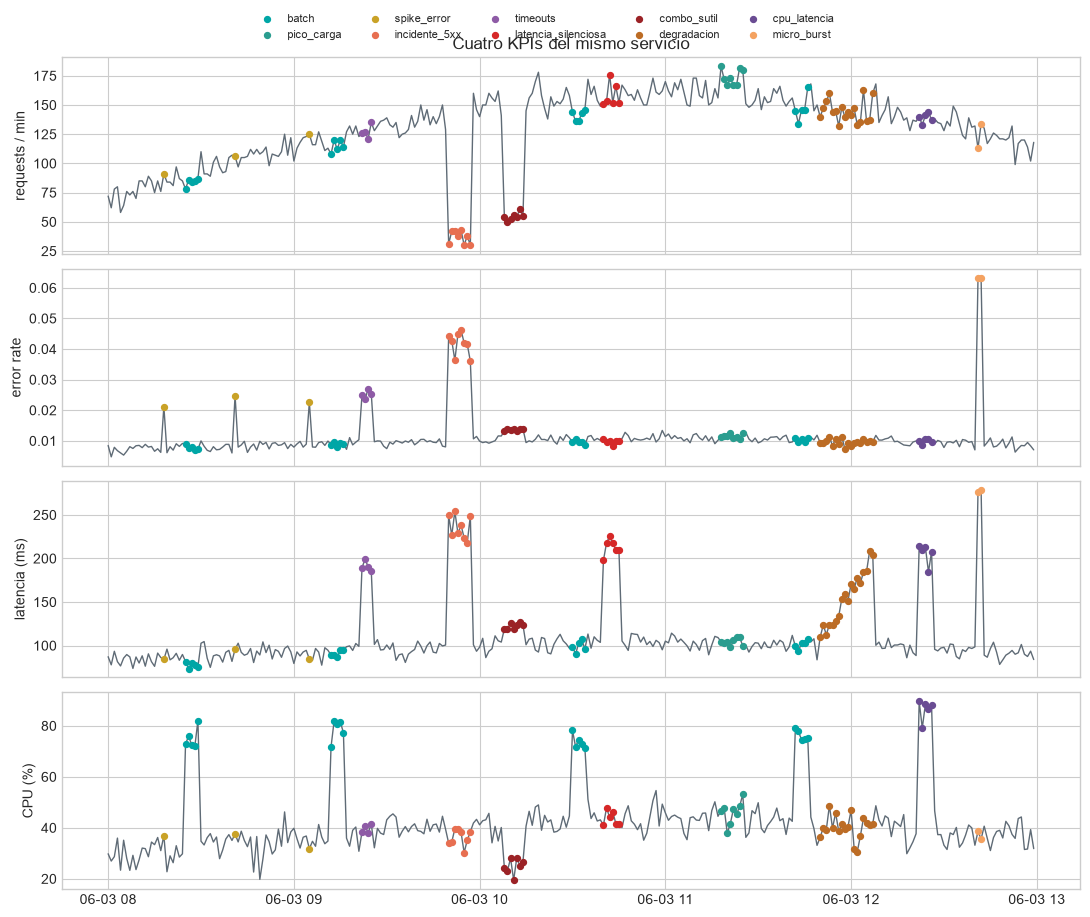

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
series = [("requests", "requests / min"), ("error_rate", "error rate"), ("latency_ms", "latencia (ms)"), ("cpu_pct", "CPU (%)")]
for ax, (col, ylabel) in zip(axes, series):
    ax.plot(data["timestamp"], data[col], color=GRAY, lw=1.0)
    for name, color in KIND_COLORS.items():
        if name == "normal":
            continue
        mask = data["kind"].eq(name)
        ax.scatter(data.loc[mask, "timestamp"], data.loc[mask, col], c=color, s=18, zorder=3, label=name)
    ax.set_ylabel(ylabel)
axes[0].set_title("Cuatro KPIs del mismo servicio")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.02), fontsize=8)
plt.tight_layout()
plt.show()


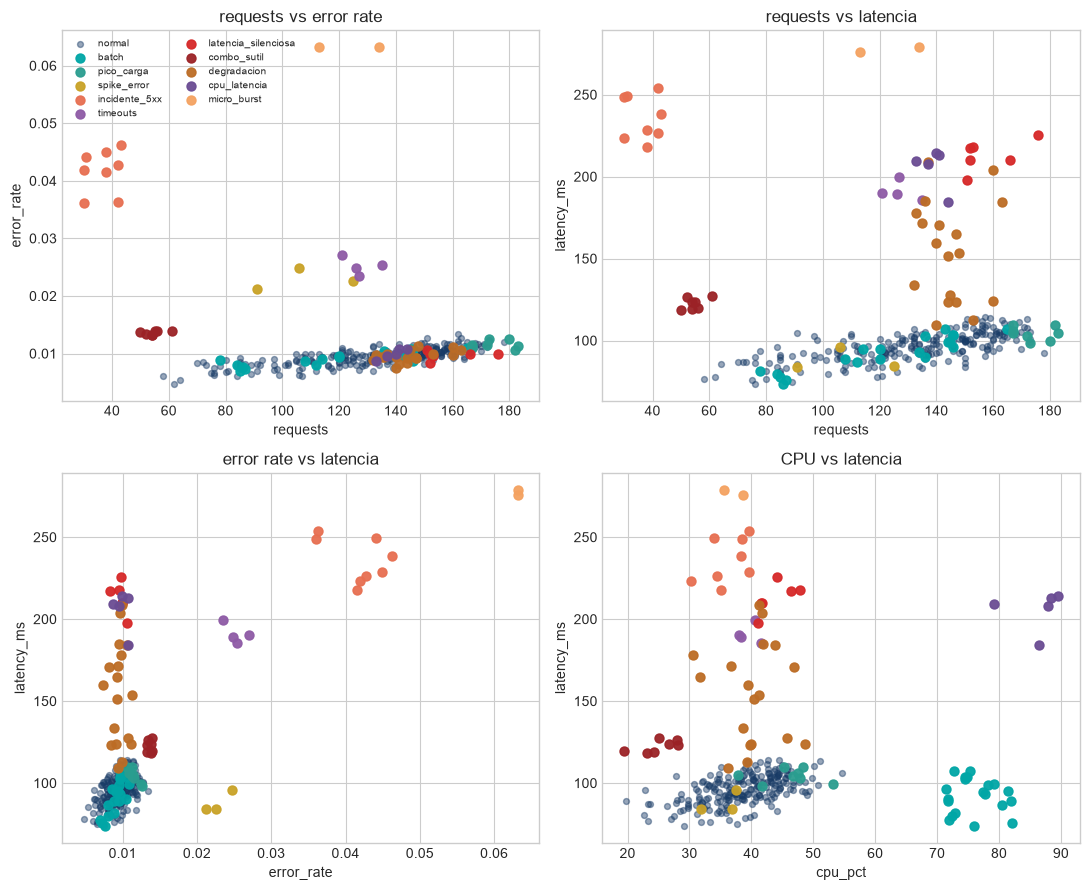

In [4]:
planes = [
    ("requests", "error_rate", "requests vs error rate"),
    ("requests", "latency_ms", "requests vs latencia"),
    ("error_rate", "latency_ms", "error rate vs latencia"),
    ("cpu_pct", "latency_ms", "CPU vs latencia"),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (a, b, title) in zip(axes.ravel(), planes):
    for name, color in KIND_COLORS.items():
        mask = data["kind"].eq(name)
        ax.scatter(
            data.loc[mask, a], data.loc[mask, b],
            c=color, s=18 if name == "normal" else 42,
            alpha=0.45 if name == "normal" else 0.95,
            label=name, zorder=2 if name == "normal" else 3,
        )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(title)
axes[0, 0].legend(loc="upper left", fontsize=7, ncol=2)
plt.tight_layout()
plt.show()


## 3. Protocolo de entrenamiento

Igual que Isolation Forest en la clase 10: **no hay etiquetas para aprender**. Estimamos todo sobre las 300 ventanas.

- Univariados: $\mu,\sigma$ y mediana/MAD se estiman sobre **toda** la serie. La muestra está contaminada (incidentes, spikes). Eso es el punto: k-sigma se deja llevar, MAD no.
- Isolation Forest y One-Class SVM se entrenan sobre las cuatro features **escaladas**, también sin `kind`.
- `contamination=0.10` y `nu=0.10` son un presupuesto de alertas (~30 minutos), no la tasa verdadera (~17%).
- `pico_carga` y `batch` están marcados como *no anómalos*: son trampas. Si un detector los enciende, es un falso positivo con historia operativa.


In [5]:
print("Minutos por kind:")
display(data["kind"].value_counts().rename("n").to_frame())

scaler = StandardScaler().fit(data[FEATURES])
X_all = scaler.transform(data[FEATURES])
print("Medias del scaler:", dict(zip(FEATURES, scaler.mean_.round(3))))
print("Escalas del scaler:", dict(zip(FEATURES, scaler.scale_.round(3))))


Minutos por kind:


,n
kind,
normal,219
batch,20
degradacion,18
incidente_5xx,8
pico_carga,8
combo_sutil,7
latencia_silenciosa,6
cpu_latencia,5
timeouts,4


Medias del scaler: {'requests': np.float64(128.497), 'error_rate': np.float64(0.011), 'latency_ms': np.float64(110.465), 'cpu_pct': np.float64(41.745)}
Escalas del scaler: {'requests': np.float64(32.487), 'error_rate': np.float64(0.007), 'latency_ms': np.float64(38.48), 'cpu_pct': np.float64(12.56)}


## 4. k-sigma (univariado)

Sobre una serie $x_1,\dots,x_n$ (acá, las 300 ventanas):

$$
\hat\mu=\bar x,\qquad
\hat\sigma=\sqrt{\frac1{n-1}\sum_i(x_i-\hat\mu)^2},\qquad
s_k(x)=\left|\frac{x-\hat\mu}{\hat\sigma}\right|.
$$

Alerta si $s_k(x)>k$. Usamos $k=3$. Aplíquenlo a `error_rate` y a `latency_ms`.

Ojo: los tres `spike_error` y los incidentes grandes están *dentro* de la muestra. Inflan $\hat\sigma$ del error rate. Eso es parte del ejercicio.


In [6]:
def k_sigma_fit(series: pd.Series):
    # Devuelve (mu, sigma) estimados sobre la serie, con ddof=1.
    mu = float(series.mean())
    sigma = float(series.std(ddof=1))
    return mu, sigma


def k_sigma_score(series: pd.Series, mu: float, sigma: float):
    # Score |x - mu| / sigma, alineado con el indice de series.
    return ((series - mu) / sigma).abs()


K = 3.0
mu_err, sig_err = k_sigma_fit(data["error_rate"])
mu_lat, sig_lat = k_sigma_fit(data["latency_ms"])
data["score_ksigma_error"] = k_sigma_score(data["error_rate"], mu_err, sig_err)
data["score_ksigma_lat"] = k_sigma_score(data["latency_ms"], mu_lat, sig_lat)
data["flag_ksigma_error"] = data["score_ksigma_error"] > K
data["flag_ksigma_lat"] = data["score_ksigma_lat"] > K

print(f"error_rate  μ={mu_err:.4f}  σ={sig_err:.4f}  umbral 3σ={mu_err + 3 * sig_err:.4f}")
print(f"latency_ms  μ={mu_lat:.2f}  σ={sig_lat:.2f}  umbral 3σ={mu_lat + 3 * sig_lat:.1f}")
print("Alertas k-sigma error:", int(data.flag_ksigma_error.sum()), "| latencia:", int(data.flag_ksigma_lat.sum()))

error_rate  μ=0.0112  σ=0.0072  umbral 3σ=0.0328
latency_ms  μ=110.47  σ=38.54  umbral 3σ=226.1
Alertas k-sigma error: 10 | latencia: 8


## 5. MAD / z-score robusto (univariado)

$$
\widetilde x=\operatorname{median}(x_i),\qquad
\operatorname{MAD}=\operatorname{median}(|x_i-\widetilde x|),\qquad
\widehat\sigma_{\mathrm{MAD}}=1.4826\,\operatorname{MAD}.
$$

$$
s_r(x)=\left|\frac{x-\widetilde x}{\widehat\sigma_{\mathrm{MAD}}}\right|.
$$

Alerta si $s_r(x)>k$, otra vez $k=3$. La constante $1.4826$ hace que, si $x$ fuera normal, $\widehat\sigma_{\mathrm{MAD}}$ estime $\sigma$. Mediana y MAD toleran hasta casi un $50\%$ de contaminación; los tres spikes no deberían desplazarlos.


In [7]:
def mad_fit(series: pd.Series):
    # Devuelve (mediana, MAD, escala=1.4826*MAD).
    med = float(series.median())
    mad = float((series - med).abs().median())
    scale = 1.4826 * mad
    return med, mad, scale


def mad_score(series: pd.Series, med: float, scale: float):
    # Score |x - mediana| / escala. Si escala==0, devolver 0 en la mediana e inf fuera.
    dev = (series - med).abs()
    if scale == 0:
        return dev.where(dev == 0, np.inf)
    return dev / scale


med_err, mad_err, scale_err = mad_fit(data["error_rate"])
med_lat, mad_lat, scale_lat = mad_fit(data["latency_ms"])
data["score_mad_error"] = mad_score(data["error_rate"], med_err, scale_err)
data["score_mad_lat"] = mad_score(data["latency_ms"], med_lat, scale_lat)
data["flag_mad_error"] = data["score_mad_error"] > K
data["flag_mad_lat"] = data["score_mad_lat"] > K

print(f"error_rate  mediana={med_err:.4f}  MAD={mad_err:.4f}  escala={scale_err:.4f}  (σ k-sigma={sig_err:.4f})")
print(f"latency_ms  mediana={med_lat:.2f}  MAD={mad_lat:.2f}  escala={scale_lat:.2f}  (σ k-sigma={sig_lat:.2f})")
print("Alertas MAD error:", int(data.flag_mad_error.sum()), "| latencia:", int(data.flag_mad_lat.sum()))

error_rate  mediana=0.0097  MAD=0.0010  escala=0.0016  (σ k-sigma=0.0072)
latency_ms  mediana=99.22  MAD=7.84  escala=11.62  (σ k-sigma=38.54)
Alertas MAD error: 18 | latencia: 36


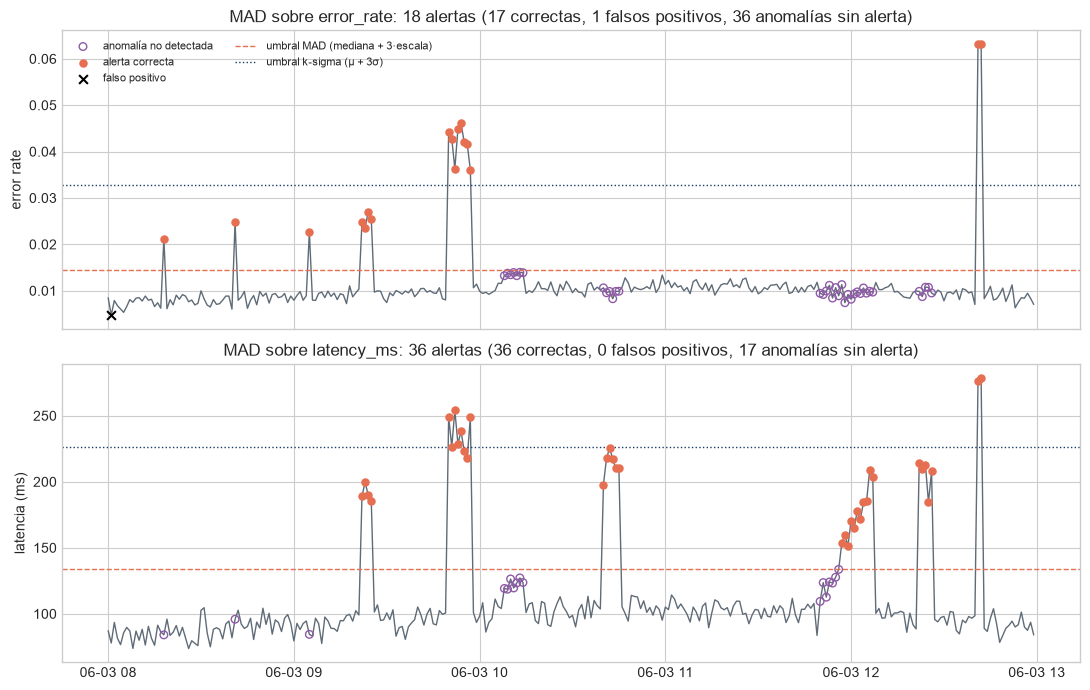

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
panels = [
    ("error_rate", "flag_mad_error", med_err, scale_err, mu_err, sig_err, "error rate"),
    ("latency_ms", "flag_mad_lat", med_lat, scale_lat, mu_lat, sig_lat, "latencia (ms)"),
]
for ax, (col, flag_col, med, scale, mu, sig, ylabel) in zip(axes, panels):
    flags = data[flag_col]
    tp = flags & data["is_anomaly"]
    fp = flags & ~data["is_anomaly"]
    fn = ~flags & data["is_anomaly"]
    ax.plot(data["timestamp"], data[col], color=GRAY, lw=1.0, zorder=1)
    ax.scatter(data.loc[fn, "timestamp"], data.loc[fn, col], facecolors="none", edgecolors=PURPLE, s=30, label="anomalía no detectada", zorder=2)
    ax.scatter(data.loc[tp, "timestamp"], data.loc[tp, col], c=ORANGE, s=26, label="alerta correcta", zorder=3)
    ax.scatter(data.loc[fp, "timestamp"], data.loc[fp, col], c="black", marker="x", s=40, label="falso positivo", zorder=4)
    ax.axhline(med + K * scale, color=ORANGE, ls="--", lw=1, label="umbral MAD (mediana + 3·escala)")
    ax.axhline(mu + K * sig, color=BLUE, ls=":", lw=1, label="umbral k-sigma (μ + 3σ)")
    ax.set_ylabel(ylabel)
    ax.set_title(f"MAD sobre {col}: {int(flags.sum())} alertas ({int(tp.sum())} correctas, {int(fp.sum())} falsos positivos, {int(fn.sum())} anomalías sin alerta)")
axes[0].legend(loc="upper left", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 6. Isolation Forest (multivariado, 4D)

Entrenen sobre `X_all` (300 ventanas ya escaladas). `contamination` es una **política** de recorte, no un diagnóstico: acá $0.10$.

Score para ranking, igual que en la clase 10:

$$
\mathrm{score}_{\mathrm{IF}}(x)=-\texttt{score\_samples}(x).
$$

Flag: `predict == -1`. Features: las cuatro.


In [ ]:
# TODO: instanciar IsolationForest (n_estimators=300, max_samples=min(256, len(data)),
#       contamination=0.10, random_state=42), fit sobre X_all.
forest = None  # TODO

# TODO: data["score_if"] = -forest.score_samples(X_all)
# TODO: data["flag_if"] = forest.predict(X_all) == -1

print("Alertas Isolation Forest:", int(data.flag_if.sum()) if "flag_if" in data else "pendiente")


## 7. One-Class SVM RBF (multivariado, 4D)

Mismas 300 ventanas, mismas features escaladas. Kernel RBF, `nu=0.10`, `gamma="scale"`.

$$
f(x)=\sum_{i\in\mathrm{SV}}\alpha_i\,k(x_i,x)-\rho,\qquad
\mathrm{score}_{\mathrm{OCSVM}}(x)=-f(x).
$$

Flag: `predict == -1` (equivalente a $f(x)<0$).


In [ ]:
# TODO: OneClassSVM(kernel="rbf", nu=0.10, gamma="scale"), fit sobre X_all.
ocsvm = None  # TODO

# TODO: data["score_ocsvm"] = -ocsvm.decision_function(X_all)
# TODO: data["flag_ocsvm"] = ocsvm.predict(X_all) == -1

print("Alertas One-Class SVM:", int(data.flag_ocsvm.sum()) if "flag_ocsvm" in data else "pendiente")


## 8. Comparación

Cada fila es un `kind`. Cada columna cuenta **minutos alertados**. Un detector univariado sobre error rate no tiene por qué ver `latencia_silenciosa`. Un detector 4D no tiene por qué perdonar el `combo_sutil`. `batch` y `pico_carga` son el test de falsos positivos.


In [ ]:
FLAG_COLS = {
    "k-sigma error": "flag_ksigma_error",
    "k-sigma lat": "flag_ksigma_lat",
    "MAD error": "flag_mad_error",
    "MAD lat": "flag_mad_lat",
    "Isolation Forest": "flag_if",
    "One-Class SVM": "flag_ocsvm",
}

missing = [c for c in FLAG_COLS.values() if c not in data.columns]
if missing:
    raise RuntimeError(f"Faltan columnas {missing}. Completá las secciones 4-7 antes de comparar.")

counts = data.groupby("kind")[list(FLAG_COLS.values())].sum().astype(int)
counts.columns = list(FLAG_COLS)
counts["n"] = data.groupby("kind").size()
counts["anómalo?"] = data.groupby("kind")["is_anomaly"].any()
display(counts[["n", "anómalo?", *FLAG_COLS]])

score_cols = {
    "k-sigma error": "score_ksigma_error",
    "k-sigma lat": "score_ksigma_lat",
    "MAD error": "score_mad_error",
    "MAD lat": "score_mad_lat",
    "IF": "score_if",
    "OCSVM": "score_ocsvm",
}
print("Mediana del score por kind (el ranking, no la flag):")
display(data.groupby("kind")[list(score_cols.values())].median().round(3).rename(columns={v: k for k, v in score_cols.items()}))


In [ ]:
def prf(flag_col, mask=None):
    sel = data if mask is None else data.loc[mask]
    p, r, f1, _ = precision_recall_fscore_support(
        sel["is_anomaly"], sel[flag_col], average="binary", zero_division=0,
    )
    return pd.Series({"precision": p, "recall": r, "f1": f1, "alertas": int(sel[flag_col].sum())})


metrics_all = pd.DataFrame({name: prf(col) for name, col in FLAG_COLS.items()}).T
print("Sobre las 300 ventanas (is_anomaly vs flag):")
display(metrics_all.round(3))


In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8.2), sharex=True)
axes[0].plot(data["timestamp"], data["score_ksigma_error"], color=BLUE, lw=1.1, label="k-sigma error")
axes[0].plot(data["timestamp"], data["score_mad_error"], color=ORANGE, lw=1.1, label="MAD error")
axes[0].axhline(3, color=GRAY, ls="--", lw=1)
axes[0].set_ylabel("score univariado")
axes[0].legend(loc="upper left")

axes[1].plot(data["timestamp"], data["score_if"], color=BLUE, lw=1.1, label="IF")
axes[1].scatter(data.loc[data["flag_if"], "timestamp"], data.loc[data["flag_if"], "score_if"], c=ORANGE, s=16)
axes[1].set_ylabel("score IF")
axes[1].legend(loc="upper left")

axes[2].plot(data["timestamp"], data["score_ocsvm"], color=BLUE, lw=1.1, label="OCSVM")
axes[2].scatter(data.loc[data["flag_ocsvm"], "timestamp"], data.loc[data["flag_ocsvm"], "score_ocsvm"], c=ORANGE, s=16)
axes[2].set_ylabel("score OCSVM")
axes[2].legend(loc="upper left")
axes[0].set_title("Scores en el tiempo  |  la línea punteada es k=3 para los univariados")
plt.tight_layout()
plt.show()


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, flag_col, title in zip(axes, ("flag_if", "flag_ocsvm"), ("Isolation Forest", "One-Class SVM")):
    flags = data[flag_col]
    ax.scatter(data.loc[~flags, "requests"], 100 * data.loc[~flags, "error_rate"], c=BLUE, s=16, alpha=0.55, label="habitual")
    ax.scatter(data.loc[flags, "requests"], 100 * data.loc[flags, "error_rate"], c=ORANGE, s=38, label="alerta")
    ax.set_title(title)
    ax.set_xlabel("requests / min")
    ax.legend(loc="upper left")
axes[0].set_ylabel("error rate (%)")
plt.suptitle("Proyección 2D de un recorte 4D: no es toda la historia, pero se lee el incidente")
plt.tight_layout()
plt.show()


## 9. Preguntas (para entregar / discutir)

Respondan con evidencia de las tablas y gráficos, no con la definición del método.

1. Comparen $\sigma$ de k-sigma contra la escala MAD en `error_rate`. ¿Qué le hicieron los `spike_error` y el `micro_burst` a cada una? ¿Se ve el mismo efecto en `latency_ms`?
2. ¿Qué kinds prende k-sigma sobre error rate y **no** prende sobre latencia? ¿Y al revés? ¿Por qué `latencia_silenciosa` es el ejemplo canónico?
3. ¿Algún minuto de `combo_sutil` cruza $k=3$ en un eje solo? Si no, ¿lo ranquean IF u OCSVM cerca de la cima aunque la flag no se encienda?
4. Tomen un minuto de `pico_carga` y uno de `incidente_5xx`. En el plano requests–error rate, ¿quién está al borde de la nube y quién afuera? ¿Coinciden las flags 4D con esa geometría?
5. El `batch` es legítimo. ¿Qué detector lo trata como anomalía y por qué un modo raro (aunque operativo) se parece a un outlier?
6. En `degradacion`, ¿cuál es el primer minuto que cada método enciende? ¿Qué le falta a un detector i.i.d. minuto a minuto?
7. `nu=0.10` y `contamination=0.10` recortan más o menos el mismo presupuesto de alertas. ¿Obtienen el mismo F1? Si no, ¿dónde se pelean?

### Exit ticket

Elijan **un** falso negativo y **un** falso positivo de cualquier método. Para cada uno: el vector $\mathbf x_t$, qué pregunta hacía el detector, y qué cambiarían (feature, umbral o ventana de train) sin romper el resto.
